# Pulse sweeps — how the connectivity profile changes with the pulse's height, width and position

Each of the three controls of the cosine bump is pulsed: **width_scale** (bump width), **gain** (speed) and
**amplitude**. Three sweeps per control, each around a default with the other two fixed:
- **height**;
- **width** (SD of the pulse);
- **position** (time of the pulse peak).

The protocol and the per-neuron connectivity profiles are those of `pulsed_testbed.ipynb`:
- one fixed one-pass snippet from t = 0, 6 networks per condition;
- incoming profile P[n, d] = W[n, n + d], with negative d meaning input from earlier neurons;
- each condition compared with the unpulsed control, realization by realization. The same seed gives paired J0 and
  noise.

**What is measured** for each condition, along the sequence (neurons in snippet order, interior only):
- **change magnitude** m(s) = ‖P_pulsed(s, ·) − P_control(s, ·)‖ over d, after smoothing over neurons and removing
  the noise level. Its peak and full width at half maximum (FWHM) give where, and over how many neurons, the pulse
  changed the connectivity;
- the **asymmetry** and the **stretch** of each profile relative to the control's mean profile;
- the **speed implied by the harmonics** (Im λ_k = c·k·Re λ_k fitted over k = 1–4 of the local profile), relative to
  the control. It is meaningful for the gain (speed) pulses only; under the methods convention the shape pulses also
  move it;
- the **at-pulse changes**: paired feature changes for the neurons within ±20 of the pulse neuron;
- the **main shape of change** (difference mode 1).

Settings: `configs/pulsed/pulsed_sweep.yaml`. Training: `python -m seqnet.experiments.pulsed configs/pulsed/pulsed_sweep.yaml`
(cached runs are reused, including the testbed's).

**Panels:**
- A: targets
- B: training
- C: signatures along the sequence
- D: dose–response at the pulse
- E: where and how wide the change is
- F: the shape of the change
- G: ridgelines of the strongest pulses
- H: harmonic signatures
- I: checks

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from seqnet.figures import Figure, style
from seqnet.analysis import neuron_profiles as npf
from seqnet.experiments import pulsed as pz
from seqnet.plotting import profiles as pp
from seqnet.sequences import build_sequence
from seqnet.training.config import ForceConfig

style()
fig = Figure("pulsed", "pulsed_sweep")
sw = fig.config()
N, an, tr = sw["N"], sw["analysis"], sw["training"]
tau = ForceConfig().tau
conds = pz.sweep_conditions(sw)
runs = pz.train_sweep(sw)  # loads the cache; trains what is missing
w0, t0 = sw["default"]["width"], sw["default"]["t_peak"]


def cname(param, h, w, t):
    return f"{param}{h:+g}_w{w:g}_t{t:g}"


series = {param: {"height": [(h, cname(param, h, w0, t0)) for h in c["heights"]],
                  "width": [(w, cname(param, c["default_height"], w, t0)) for w in sw["widths"]],
                  "position": [(t, cname(param, c["default_height"], w0, t)) for t in sw["positions"]]}
          for param, c in sw["controls"].items()}
params, kinds = list(series), ("height", "width", "position")
s_pos = np.arange(N)  # snippet position (neurons from the snippet start)
interior = (s_pos >= an["edge"]) & (s_pos < N - an["edge"])
dwin = np.arange(-an["d_max"], an["d_max"] + 1)
len(conds), {p: {k: [v for v, _ in series[p][k]] for k in kinds} for p in params}

bump                             test corr 0.847  testbed-bump-ce02c62a67


width_scale-0.6_w0.5_t4.25       test corr 0.826  testbed-width_scale-0.6_w0.5_t4.25-f58bf63cbf


width_scale-0.5_w0.5_t4.25       test corr 0.828  testbed-narrow-61dc3ccb6e


width_scale-0.3_w0.5_t4.25       test corr 0.836  testbed-width_scale-0.3_w0.5_t4.25-ea19c306bd


width_scale+0.3_w0.5_t4.25       test corr 0.855  testbed-width_scale+0.3_w0.5_t4.25-148521d6de


...

amplitude-0.5_w0.25_t4.25        test corr 0.842  testbed-amplitude-0.5_w0.25_t4.25-3979e893a4


amplitude-0.5_w1_t4.25           test corr 0.848  testbed-amplitude-0.5_w1_t4.25-b14baa360f


amplitude-0.5_w0.5_t3.5          test corr 0.844  testbed-amplitude-0.5_w0.5_t3.5-14136efd9d


amplitude-0.5_w0.5_t5            test corr 0.848  testbed-amplitude-0.5_w0.5_t5-0c77aa3024


(27,
 {'width_scale': {'height': [-0.6, -0.5, -0.3, 0.3, 0.6, 1.0],
   'width': [0.25, 0.5, 1.0],
   'position': [3.5, 4.25, 5.0]},
  'gain': {'height': [-0.6, -0.3, 0.5, 1.0, 1.5],
   'width': [0.25, 0.5, 1.0],
   'position': [3.5, 4.25, 5.0]},
  'amplitude': {'height': [-0.75, -0.5, -0.25],
   'width': [0.25, 0.5, 1.0],
   'position': [3.5, 4.25, 5.0]}})

## Analysis of every condition

For every condition, its networks and the control's are reduced to profiles in snippet order. Everything the panels
plot is computed here, condition by condition, and saved in one file.

In [2]:
ctl_name = sw["control"]


def snippet_order(seq):
    return (int(round(pz.snippet_start(seq))) + s_pos) % N


def stack(name):
    r = runs[name]
    return np.stack([r.W(i) for i in range(tr["n_realizations"])])


ctl_seq = build_sequence(conds[ctl_name][0])
o_ctl = snippet_order(ctl_seq)


def profiles(W, o):
    # (R, N, D) incoming profiles in snippet order: raw (true self-weight) and with the self-weight replaced
    raw = npf.window(npf.local_profiles(W), an["d_max"])[1][:, o]
    return raw, npf.remove_self(dwin, raw)


Wc = stack(ctl_name)
Pc_raw, Pc = profiles(Wc, o_ctl)
lam_c = npf.smooth_neurons(npf.local_spectra(npf.local_profiles(Wc).mean(0), d_max=an["spectral_d_max"])[o_ctl], an["smooth"])
sc = npf.smooth_neurons(Pc.mean(0), an["smooth"])
ref = sc[interior].mean(0)
kv = an["speed_harmonics"]
v_ref = np.median(npf.implied_speed(lam_c, kv, tau, N)[interior])

res = {"s": s_pos, "d": dwin, "ctl_asym": npf.profile_summary(dwin, sc)["asymmetry"],
       "ctl_scale": npf.dilation_fit(dwin, sc, ref, min_r2=an["stretch_min_r2"])["scale"], "ctl_v": npf.implied_speed(lam_c, kv, tau, N) / v_ref,
       "ctl_bins": npf.binned_profiles(sc, an["bin"])[0]}
for name, (spec, pulse) in conds.items():
    if pulse is None:
        continue
    seq = build_sequence(spec)
    o = snippet_order(seq)
    assert np.array_equal(o, o_ctl)  # every bump condition starts at the same neuron
    Wp = stack(name)
    Pp_raw, Pp = profiles(Wp, o)
    spp = npf.smooth_neurons(Pp.mean(0), an["smooth"])
    dP = spp - sc
    # change magnitude from the paired differences, minus its own noise level (SD over realizations / sqrt(R))
    dPr = npf.smooth_neurons(Pp - Pc, an["smooth"])
    noise = np.linalg.norm(dPr.std(0, ddof=1), axis=-1) / np.sqrt(dPr.shape[0])
    m = np.clip(np.linalg.norm(dPr.mean(0), axis=-1) - noise, 0, None)
    loc = npf.localize(s_pos[interior], m[interior])
    s_p = (pz.pulse_neuron(seq, pulse.t_peak) - pz.snippet_start(seq)) % N  # pulse neuron, snippet position
    at = np.nonzero(np.abs(s_pos - s_p) <= 20)[0]
    fp, fc = npf.profile_summary(dwin, Pp_raw[:, at].mean(1)), npf.profile_summary(dwin, Pc_raw[:, at].mean(1))
    dil_at_p, dil_at_c = npf.dilation_fit(dwin, Pp[:, at].mean(1), ref), npf.dilation_fit(dwin, Pc[:, at].mean(1), ref)
    lam_p = npf.smooth_neurons(npf.local_spectra(npf.local_profiles(Wp).mean(0), d_max=an["spectral_d_max"])[o], an["smooth"])
    modes = npf.difference_modes(dP[interior], 2)
    sv, vv = pz.speed_along_snippet(seq, pz.pass_duration(seq))
    srt = np.argsort(sv)
    lam_at = (lam_p - lam_c)[at].mean(0)[: an["harmonics"] + 1]
    res.update({
        f"{name}__m": m, f"{name}__peak": loc["peak"], f"{name}__fwhm": loc["fwhm"], f"{name}__s_p": s_p,
        f"{name}__asym": npf.profile_summary(dwin, spp)["asymmetry"],
        f"{name}__scale": npf.dilation_fit(dwin, spp, ref, min_r2=an["stretch_min_r2"])["scale"],
        f"{name}__v": npf.implied_speed(lam_p, kv, tau, N) / v_ref,
        f"{name}__vtrue": np.interp(s_pos, sv[srt], vv[srt]) / (N / (2 * t0)),
        f"{name}__dre_at": lam_at.real, f"{name}__dim_at": lam_at.imag,
        f"{name}__mode": modes["modes"][0], f"{name}__explained": modes["explained"][0],
        f"{name}__bins": npf.binned_profiles(spp, an["bin"])[0],
        f"{name}__corr": float(runs[name].summary["corr"][:, -tr["n_test"]:].mean()),
        **{f"{name}__d{f}": fp[f] - fc[f] for f in ("self", "peak", "trough", "asymmetry")},  # (R,) paired changes
        f"{name}__dscale": dil_at_p["scale"] - dil_at_c["scale"],
        f"{name}__total": float(m[interior].sum()),
    })
    del Wp, Pp, Pp_raw, dPr
res["ctl_corr"] = float(runs[ctl_name].summary["corr"][:, -tr["n_test"]:].mean())
fig.save("analysis", params={"edge": an["edge"], "smooth": an["smooth"]}, **res);

## Panel A — the targets

One pass of each condition. Rows: the controls. Columns: the swept values (heights, then widths, then positions).
White: the pulse.

In [3]:
dt_r = 0.05
out = {}
for name, (spec, pulse) in conds.items():
    seq = build_sequence(spec)
    t = np.arange(0, pz.pass_duration(seq), dt_r)
    out[f"{name}__R"] = seq.rates(t)[o_ctl][::2].astype(np.float32)
    out[f"{name}__t"] = t
fig.save("A_targets", **out);

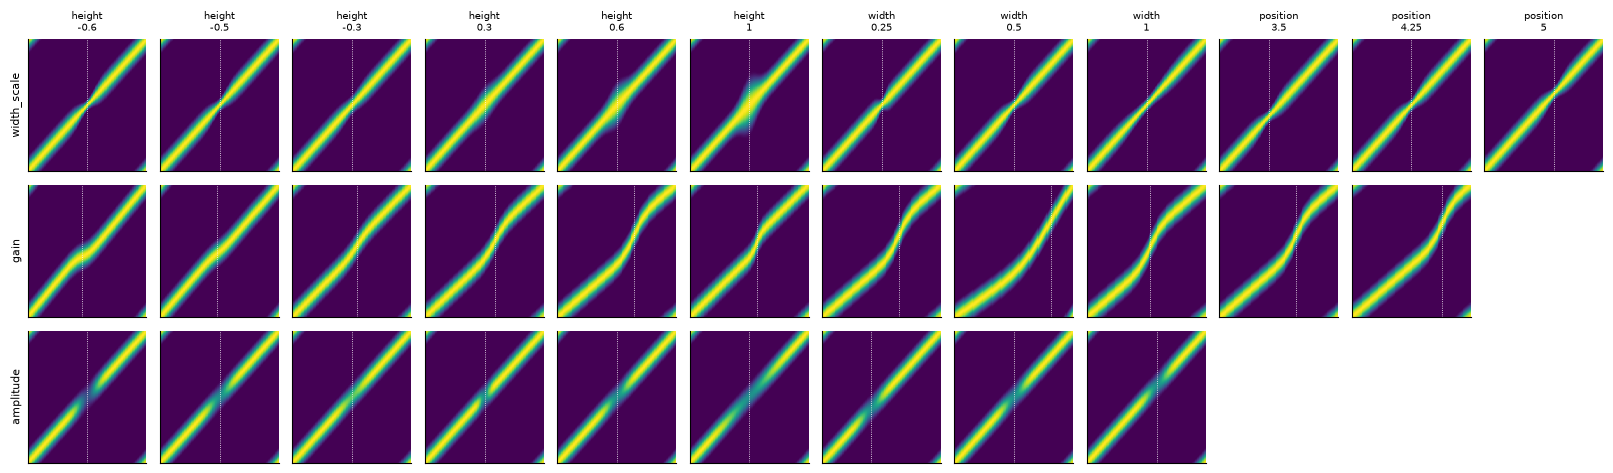

In [4]:
d = fig.load("A_targets")
row = {p: [(k, v, nm) for k in kinds for v, nm in series[p][k]] for p in params}
ncol = max(len(r) for r in row.values())
F, axs = plt.subplots(len(params), ncol, figsize=(1.35 * ncol, 1.6 * len(params)), sharey=True, squeeze=False)
for ax in axs.flat:
    ax.axis("off")
for i, p in enumerate(params):
    for j, (k, v, nm) in enumerate(row[p]):
        ax = axs[i, j]
        ax.axis("on")
        ax.imshow(d[f"{nm}__R"], aspect="auto", origin="lower", extent=[0, d[f"{nm}__t"][-1], 0, N], vmin=0, vmax=1,
                  interpolation="nearest")
        pulse = conds[nm][1]
        ax.axvline(pulse.t_peak, color="w", lw=0.6, ls=":")
        ax.set_xticks([]); ax.set_yticks([])
        if i == 0:
            ax.set_title(f"{k}\n{v:g}", fontsize=7)
    axs[i, 0].set_ylabel(p, fontsize=8)
F.tight_layout()
fig.savefig("A_targets", F); plt.show()

## Panel B — training quality

Test correlation (mean over 6 networks) against the swept value; dashed: the control.

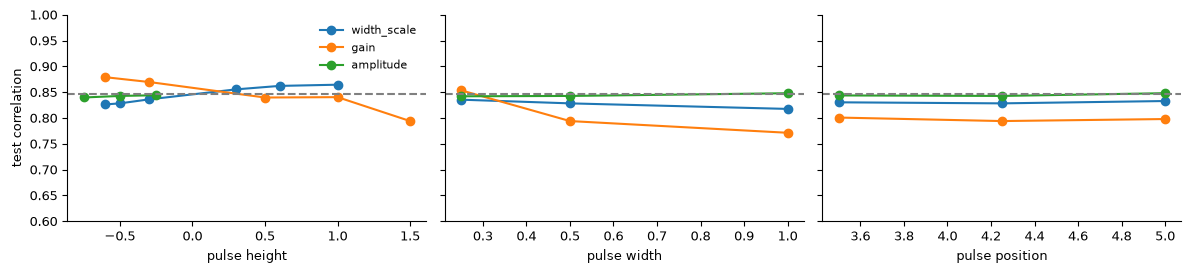

In [5]:
A = fig.load("analysis")
F, axs = plt.subplots(1, 3, figsize=(12, 2.8), sharey=True)
for ax, k in zip(axs, kinds):
    for i, p in enumerate(params):
        x = [v for v, _ in series[p][k]]
        ax.plot(x, [float(A[f"{nm}__corr"]) for _, nm in series[p][k]], "o-", color=f"C{i}", label=p)
    ax.axhline(float(A["ctl_corr"]), color="0.5", ls="--"); ax.set_xlabel(f"pulse {k}"); ax.set_ylim(0.6, 1)
axs[0].set_ylabel("test correlation"); axs[0].legend(frameon=False)
F.tight_layout()
fig.savefig("B_training", F); plt.show()

## Panel C — signatures along the sequence

One figure per control. Columns: the height, width and position sweeps, with colour running from the smallest to the
largest swept value. Rows:
1. **Change magnitude** m(s): how far each neuron's profile moved from its control.
2. **Asymmetry**: negative means input mainly from earlier neurons.
3. **Stretch** s relative to the control's mean profile.
4. **Implied speed**, from the harmonics fitted over k = 1–4, relative to the control. Thin lines: the target's actual
   bump speed relative to its baseline. Only the gain sweep changes the true speed; the other controls shift this
   reading through the bump's shape.

Grey dashed: the control. Ticks on the x axis: each condition's pulse neuron.

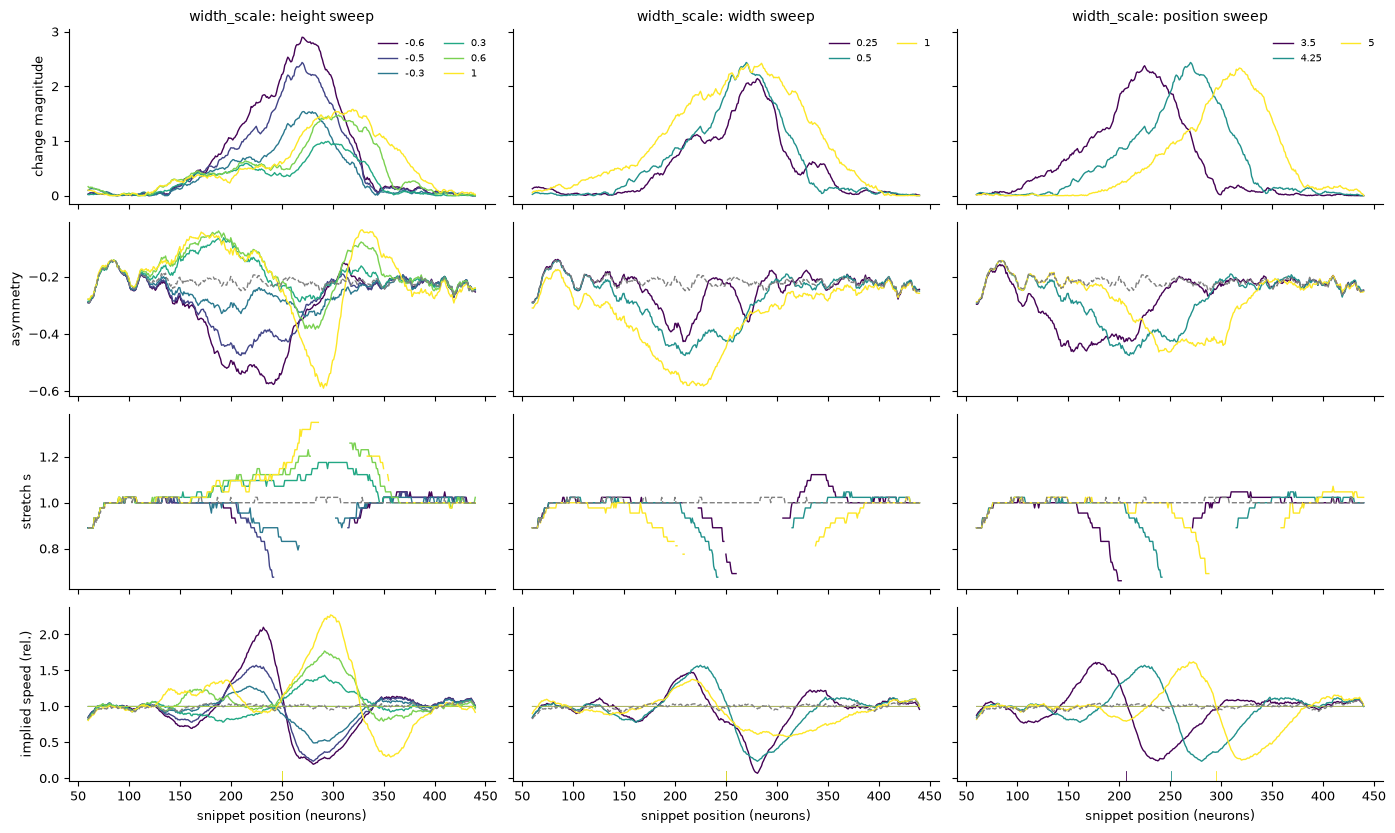

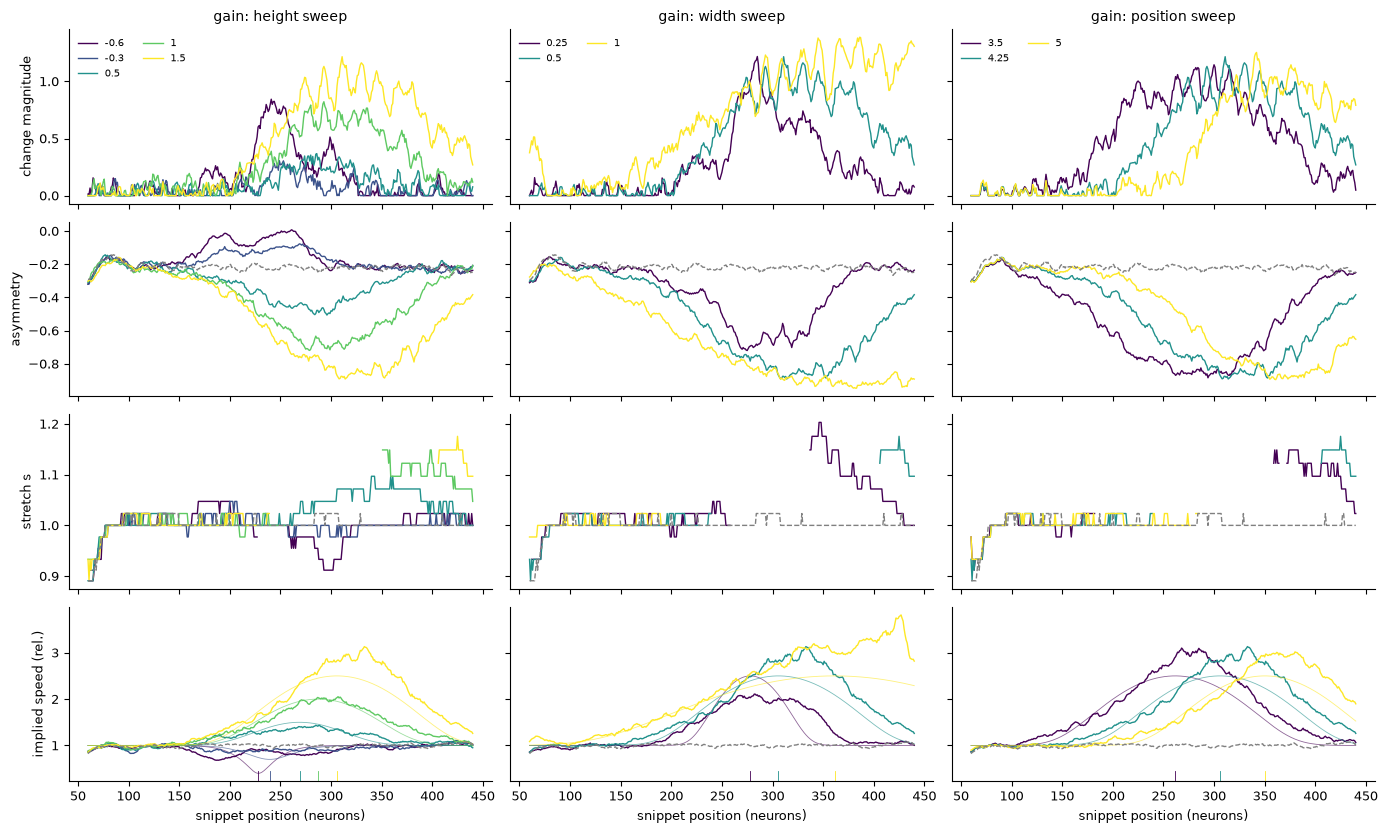

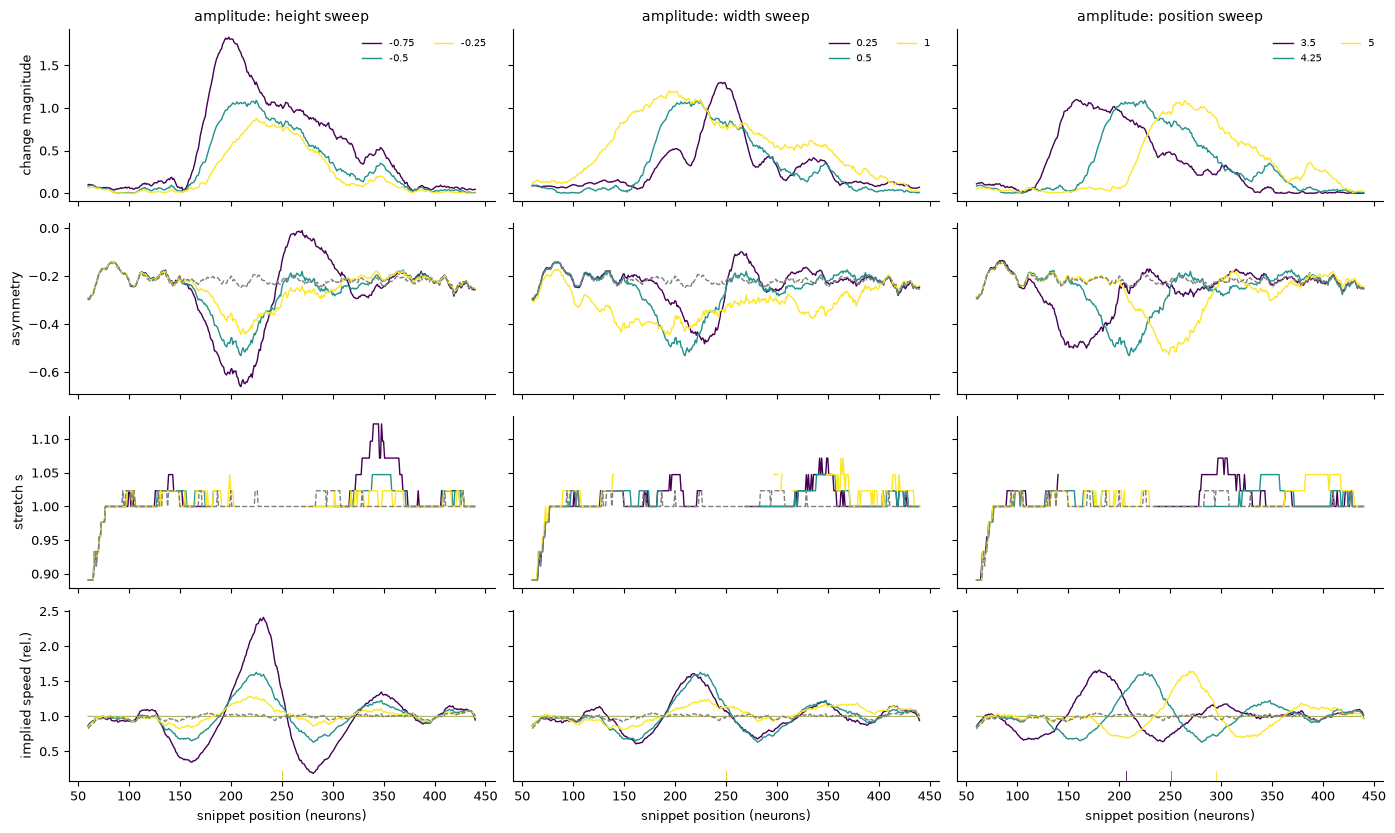

In [6]:
A = fig.load("analysis")
rows = (("m", "change magnitude"), ("asym", "asymmetry"), ("scale", "stretch s"), ("v", "implied speed (rel.)"))
ctl_line = {"asym": A["ctl_asym"], "scale": A["ctl_scale"], "v": A["ctl_v"]}
for p in params:
    F, axs = plt.subplots(len(rows), 3, figsize=(14, 2.1 * len(rows)), sharex=True, sharey="row")
    for j, k in enumerate(kinds):
        vals = [v for v, _ in series[p][k]]
        cmap = plt.get_cmap("viridis")
        for c_, (v, nm) in enumerate(series[p][k]):
            col = cmap(c_ / max(1, len(vals) - 1))
            for i, (key, lab) in enumerate(rows):
                ax = axs[i, j]
                ax.plot(A["s"][interior], A[f"{nm}__{key}"][interior], color=col, lw=1, label=f"{v:g}" if i == 0 else None)
                if key == "v":
                    ax.plot(A["s"][interior], A[f"{nm}__vtrue"][interior], color=col, lw=0.6, alpha=0.6)
            axs[-1, j].axvline(float(A[f"{nm}__s_p"]), color=col, lw=0.6, ymax=0.06)
        for i, (key, lab) in enumerate(rows):
            if key in ctl_line:
                axs[i, j].plot(A["s"][interior], ctl_line[key][interior], color="0.5", ls="--", lw=1)
            if j == 0:
                axs[i, j].set_ylabel(lab)
        axs[0, j].set_title(f"{p}: {k} sweep"); axs[0, j].legend(frameon=False, fontsize=7, ncol=2)
        axs[-1, j].set_xlabel("snippet position (neurons)")
    F.tight_layout()
    fig.savefig(f"C_signatures_{p}", F); plt.show()

## Panel D — dose–response at the pulse

Paired changes (pulsed − control, realization by realization; mean ± SEM) of the profile features of the neurons
within ±20 of the pulse neuron, against the pulse height. The last column is the total change magnitude
Σ_s m(s) over the interior.

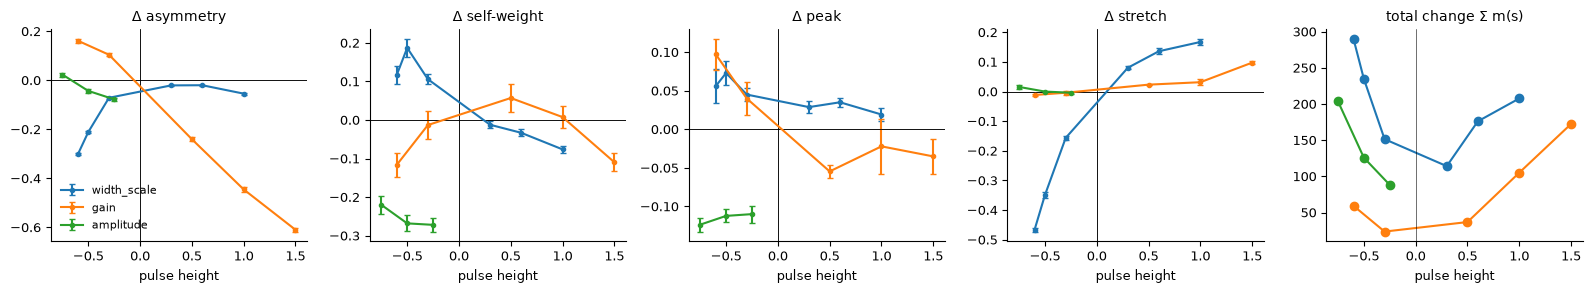

In [7]:
A = fig.load("analysis")
feats = (("dasymmetry", "Δ asymmetry"), ("dself", "Δ self-weight"), ("dpeak", "Δ peak"), ("dscale", "Δ stretch"))
F, axs = plt.subplots(1, len(feats) + 1, figsize=(16, 3))
for i, p in enumerate(params):
    h = np.array([v for v, _ in series[p]["height"]])
    for ax, (key, lab) in zip(axs, feats):
        y = np.array([A[f"{nm}__{key}"] for _, nm in series[p]["height"]])  # (heights, R)
        ax.errorbar(h, y.mean(1), y.std(1) / np.sqrt(y.shape[1]), fmt="o-", color=f"C{i}", ms=3, capsize=2, label=p)
        ax.axhline(0, color="k", lw=0.4); ax.axvline(0, color="k", lw=0.4); ax.set_title(lab); ax.set_xlabel("pulse height")
    axs[-1].plot(h, [float(A[f"{nm}__total"]) for _, nm in series[p]["height"]], "o-", color=f"C{i}", label=p)
axs[-1].set_title("total change Σ m(s)"); axs[-1].set_xlabel("pulse height"); axs[-1].axvline(0, color="k", lw=0.4)
axs[0].legend(frameon=False)
F.tight_layout()
fig.savefig("D_dose_response", F); plt.show()

## Panel E — where and how wide the change is

- **Left:** the peak of the change magnitude against the pulse neuron, for the position sweep. On the diagonal, the
  change sits exactly at the neurons active during the pulse.
- **Middle:** the change's FWHM against the pulse width in neurons. A pulse of SD w at the base speed covers
  2.355·w·N/(2·t_peak) neurons (dotted). The bump's own support, N/k neurons, adds to it.
- **Right:** FWHM against the pulse height.

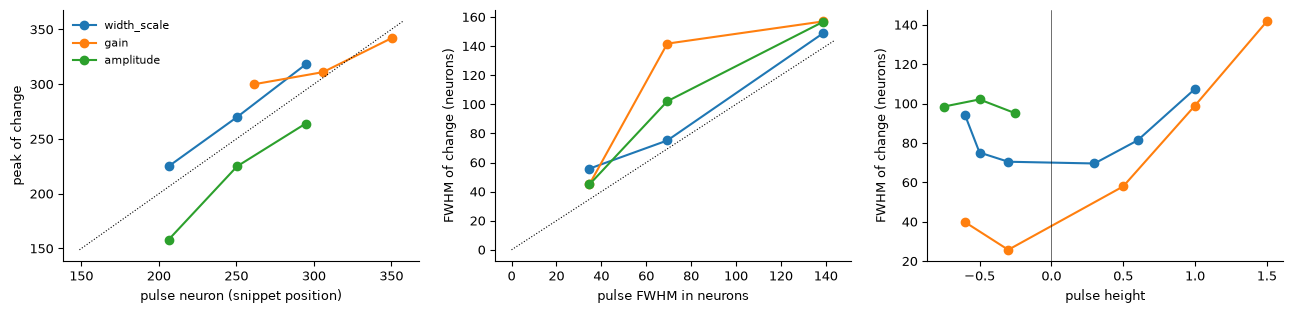

In [8]:
A = fig.load("analysis")
F, axs = plt.subplots(1, 3, figsize=(13, 3.2))
v0 = N / (2 * t0)
for i, p in enumerate(params):
    sp_ = [float(A[f"{nm}__s_p"]) for _, nm in series[p]["position"]]
    axs[0].plot(sp_, [float(A[f"{nm}__peak"]) for _, nm in series[p]["position"]], "o-", color=f"C{i}", label=p)
    wn = [2.3548 * w * v0 for w, _ in series[p]["width"]]
    axs[1].plot(wn, [float(A[f"{nm}__fwhm"]) for _, nm in series[p]["width"]], "o-", color=f"C{i}", label=p)
    axs[2].plot([h for h, _ in series[p]["height"]], [float(A[f"{nm}__fwhm"]) for _, nm in series[p]["height"]],
                "o-", color=f"C{i}", label=p)
lim = [min(axs[0].get_xlim()[0], axs[0].get_ylim()[0]), max(axs[0].get_xlim()[1], axs[0].get_ylim()[1])]
axs[0].plot(lim, lim, "k:", lw=0.8); axs[0].set_xlabel("pulse neuron (snippet position)"); axs[0].set_ylabel("peak of change")
xw = np.linspace(0, max(axs[1].get_xlim()[1], 1), 10)
axs[1].plot(xw, xw, "k:", lw=0.8); axs[1].set_xlabel("pulse FWHM in neurons"); axs[1].set_ylabel("FWHM of change (neurons)")
axs[2].set_xlabel("pulse height"); axs[2].set_ylabel("FWHM of change (neurons)"); axs[2].axvline(0, color="k", lw=0.4)
axs[0].legend(frameon=False)
F.tight_layout()
fig.savefig("E_extent", F); plt.show()

## Panel F — the shape of the change

Difference mode 1 (the main profile change over d, from an SVD across interior neurons) for every height, coloured
from the most negative to the most positive height. If one mechanism acts, the shape stays the same and only its sign
and size change with the height. Bottom: the share of the total change that mode 1 explains.

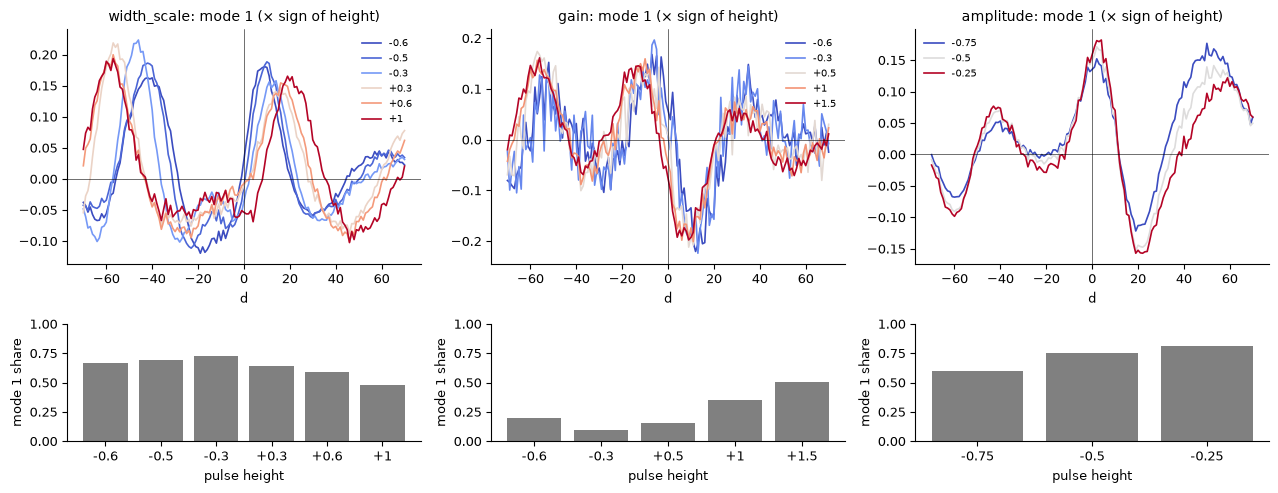

In [9]:
A = fig.load("analysis")
F, axs = plt.subplots(2, len(params), figsize=(4.3 * len(params), 5), gridspec_kw={"height_ratios": [2, 1]})
for j, p in enumerate(params):
    hs = [h for h, _ in series[p]["height"]]
    norm = plt.Normalize(min(hs), max(hs))
    for h, nm in series[p]["height"]:
        mode = A[f"{nm}__mode"] * np.sign(h)  # orient by the sign of the pulse
        axs[0, j].plot(A["d"], mode, color=plt.get_cmap("coolwarm")(norm(h)), lw=1.2, label=f"{h:+g}")
    axs[0, j].axvline(0, color="k", lw=0.4); axs[0, j].axhline(0, color="k", lw=0.4)
    axs[0, j].set_title(f"{p}: mode 1 (× sign of height)"); axs[0, j].set_xlabel("d"); axs[0, j].legend(frameon=False, fontsize=7)
    axs[1, j].bar(range(len(hs)), [float(A[f"{nm}__explained"]) for _, nm in series[p]["height"]], color="0.5")
    axs[1, j].set_xticks(range(len(hs))); axs[1, j].set_xticklabels([f"{h:+g}" for h in hs]); axs[1, j].set_ylim(0, 1)
    axs[1, j].set_ylabel("mode 1 share"); axs[1, j].set_xlabel("pulse height")
F.tight_layout()
fig.savefig("F_change_shape", F); plt.show()

## Panel G — ridgelines of the strongest pulses

Profiles every `bin` neurons (interior), stacked from the start of the snippet (bottom) to its end, for the most
negative and the most positive height of each control. Grey underneath: the control's profile for the same neurons.
The black row holds the pulse neuron.

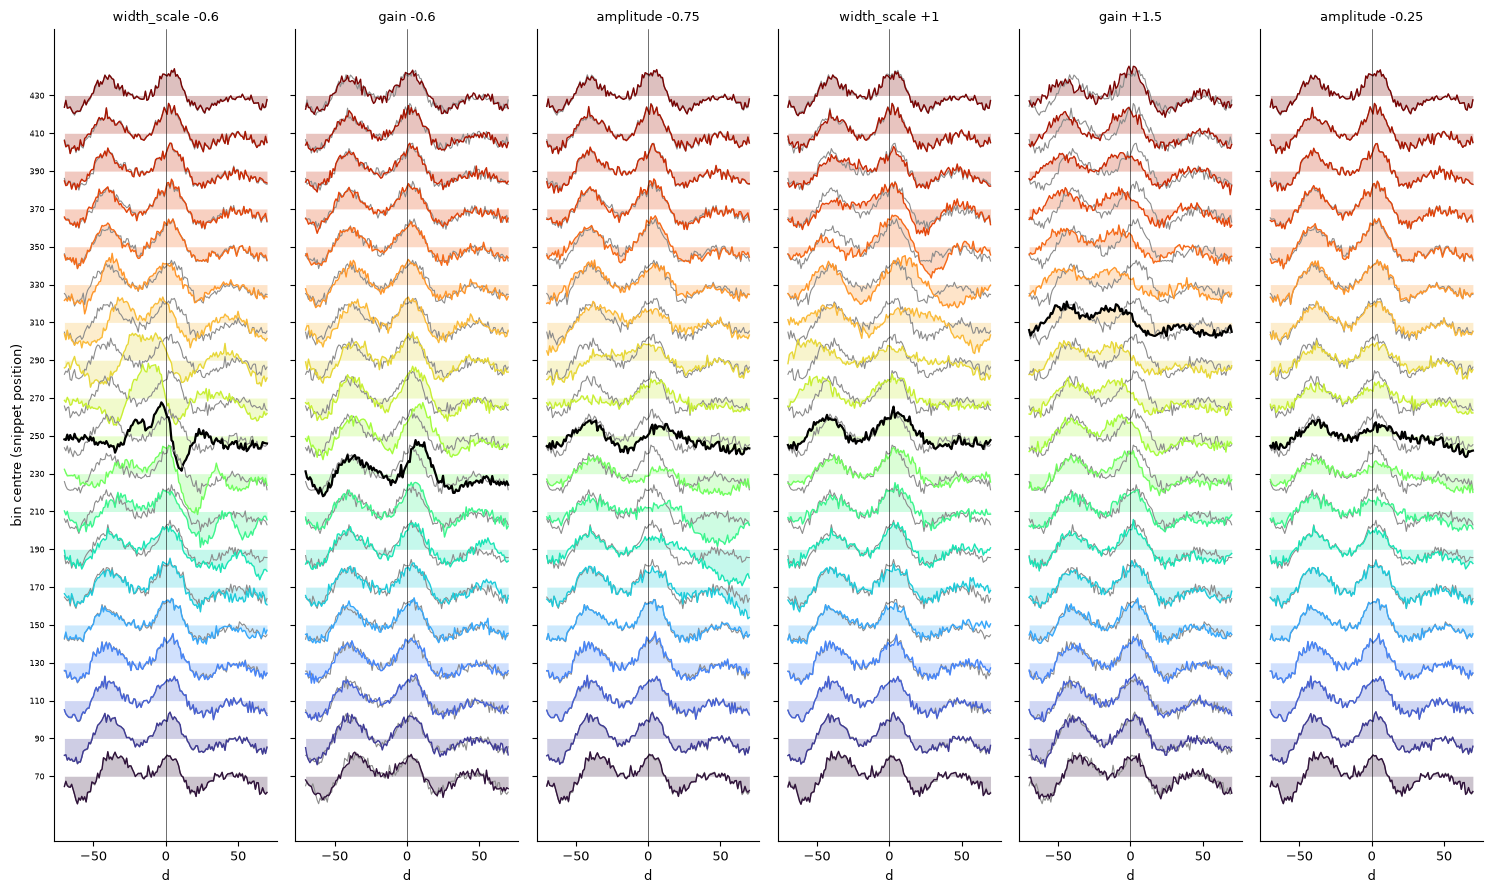

In [10]:
A = fig.load("analysis")
_, centres = npf.binned_profiles(np.zeros((N, 1)), an["bin"])
keep = (centres >= an["edge"]) & (centres < N - an["edge"])
picks = [(p, series[p]["height"][0]) for p in params] + [(p, series[p]["height"][-1]) for p in params]
F, axs = plt.subplots(1, len(picks), figsize=(2.5 * len(picks), 9), sharey=True)
spacing = 0.5 * max(np.ptp(A[f"{nm}__bins"][keep]) for _, (_, nm) in picks)
for ax, (p, (h, nm)) in zip(axs, picks):
    pp.ridgeline(ax, A["d"], A[f"{nm}__bins"][keep], centres[keep], pulse=float(A[f"{nm}__s_p"]),
                 control=A["ctl_bins"][keep], spacing=spacing)
    ax.set_title(f"{p} {h:+g}", fontsize=9); ax.set_xlabel("d")
axs[0].set_ylabel("bin centre (snippet position)")
F.tight_layout()
fig.savefig("G_ridgelines", F); plt.show()

## Panel H — harmonic signatures

The change of the local spectrum, λ_n(k) pulsed − control, averaged over the neurons at the pulse, for every height.
Re: the symmetric part. Im: the asymmetric, propagating part. Each control leaves its own spectral fingerprint:
- a width pulse redistributes power across k;
- a speed pulse moves Im λ relative to Re λ;
- an amplitude pulse scales both.

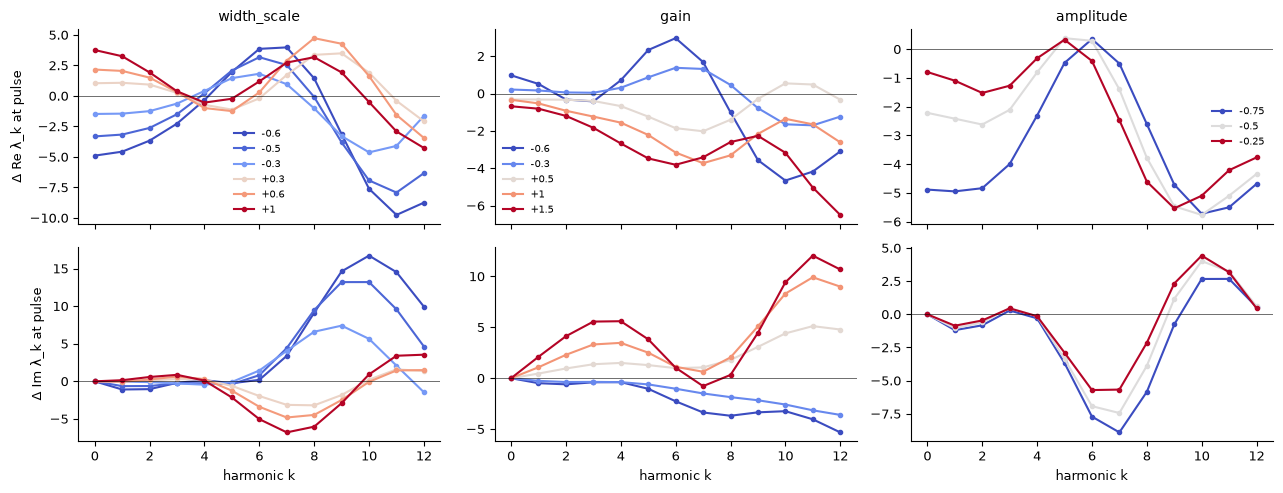

In [11]:
A = fig.load("analysis")
k = np.arange(an["harmonics"] + 1)
F, axs = plt.subplots(2, len(params), figsize=(4.3 * len(params), 5), sharex=True)
for j, p in enumerate(params):
    hs = [h for h, _ in series[p]["height"]]
    norm = plt.Normalize(min(hs), max(hs))
    for h, nm in series[p]["height"]:
        col = plt.get_cmap("coolwarm")(norm(h))
        axs[0, j].plot(k, A[f"{nm}__dre_at"], "o-", ms=3, color=col, label=f"{h:+g}")
        axs[1, j].plot(k, A[f"{nm}__dim_at"], "o-", ms=3, color=col)
    for i in range(2):
        axs[i, j].axhline(0, color="k", lw=0.4)
    axs[0, j].set_title(p); axs[0, j].legend(frameon=False, fontsize=7)
    axs[1, j].set_xlabel("harmonic k")
axs[0, 0].set_ylabel("Δ Re λ_k at pulse"); axs[1, 0].set_ylabel("Δ Im λ_k at pulse")
F.tight_layout()
fig.savefig("H_harmonics", F); plt.show()

## Panel I — checks

The localization tolerance is the bump's half-support, N/(2k): a pulse at one moment touches every neuron active
then. Dose–response is tested within each sign of the pulse, because pulses of opposite sign are different
perturbations, not the same one scaled.

In [12]:
from scipy.stats import spearmanr

A = fig.load("analysis")
checks = [{"item": "every condition trains (test corr > 0.7)",
           "value": round(min(float(A[f"{nm}__corr"]) for nm, (_, pl) in conds.items() if pl is not None), 3),
           "passed": min(float(A[f"{nm}__corr"]) for nm, (_, pl) in conds.items() if pl is not None) > 0.7}]
for p in params:
    half = N / (2 * sw["base"]["k"])  # the bump's half-support: neurons co-active with the pulse neuron
    err = [float(A[f"{nm}__peak"]) - float(A[f"{nm}__s_p"]) for _, nm in series[p]["position"]]
    checks.append({"item": f"{p}: change peaks within the bump's half-support ({half:.0f}) of the pulse neuron "
                           "(peak - pulse neuron, neurons)", "value": np.round(err, 1).tolist(),
                   "passed": max(abs(e) for e in err) < half})
    for sign, lab in ((-1, "negative"), (1, "positive")):
        hs = sorted((abs(v), float(A[f"{nm}__total"])) for v, nm in series[p]["height"] if np.sign(v) == sign)
        if len(hs) >= 2:
            checks.append({"item": f"{p}: total change grows with |height| ({lab} pulses)",
                           "value": {f"{h:g}": round(t, 1) for h, t in hs},
                           "passed": bool(np.all(np.diff([t for _, t in hs]) > 0))})
    wf = [float(A[f"{nm}__fwhm"]) for _, nm in series[p]["width"]]
    checks.append({"item": f"{p}: the change widens with the pulse width (FWHM, neurons)", "value": np.round(wf, 1).tolist(),
                   "passed": bool(np.all(np.diff(wf) > 0))})
for h, nm in series["gain"]["height"]:
    c = float(np.corrcoef(A[f"{nm}__v"][interior], A[f"{nm}__vtrue"][interior])[0, 1])
    checks.append({"item": f"gain {h:+g}: implied speed follows the target speed (corr, interior)", "value": round(c, 3),
                   "passed": c > 0.7})
fig.checks(checks);

[PASS] every condition trains (test corr > 0.7): 0.771
[PASS] width_scale: change peaks within the bump's half-support (63) of the pulse neuron (peak - pulse neuron, neurons): [18.7, 19.5, 23.3]
[PASS] width_scale: total change grows with |height| (negative pulses): {'0.3': 151.4, '0.5': 234.7, '0.6': 289.9}
[PASS] width_scale: total change grows with |height| (positive pulses): {'0.3': 114.1, '0.6': 176.1, '1': 207.7}
[PASS] width_scale: the change widens with the pulse width (FWHM, neurons): [55.8, 75.1, 148.8]
[PASS] gain: change peaks within the bump's half-support (63) of the pulse neuron (peak - pulse neuron, neurons): [38.3, 5.1, -8.1]
[PASS] gain: total change grows with |height| (negative pulses): {'0.3': 23.7, '0.6': 59.3}
[PASS] gain: total change grows with |height| (positive pulses): {'0.5': 36.8, '1': 105.1, '1.5': 172.4}
[PASS] gain: the change widens with the pulse width (FWHM, neurons): [45.0, 141.7, 157.0]
[PASS] amplitude: change peaks within the bump's half-support 

## What the sweeps show (6 networks per condition, reduced settings)

**Where.** The change is confined to the neurons active around the pulse:
- it moves with the pulse position (Panel E, left);
- its width is the pulse's extent plus about the bump's support (Panel E, middle);
- neurons a few bump-widths away keep the control's profile (Panels C and G).

The amplitude pulse is the exception in detail: its change peaks 25–50 neurons *before* the pulse neuron, still
within the bump's half-support.

**What.** Each control leaves its own signature:
- **Width** (width_scale) acts on the profile's *scale*.
  - Narrowing compresses the profile toward d = 0 (stretch down to ≈ 0.5) and makes the input more feed-forward
    (Δ asymmetry ≈ −0.3 at −0.6).
  - Widening stretches it (s up to ≈ 1.17).
  - The response is asymmetric: narrowing changes the connectivity 1.3–1.7× as much as widening by the same
    amount (Panel D).
- **Speed** (gain) acts on the *asymmetry*.
  - Faster pulses make the input more feed-forward, almost linearly in the height (Δ asymmetry ≈ −0.6 at +1.5).
  - Slower pulses make it more symmetric.
  - For faster pulses the harmonics give a quantitative local speed (correlation 0.90–0.97 with the target's speed).
  - Slowed pulses cover few neurons, and their harmonic speed reading is weak. The asymmetry reports them better.
- **Amplitude** acts on the *gain*: a uniform drop of self-weight and peak (≈ −0.27 and −0.12), with almost no change
  of asymmetry or stretch. Its change has one stable shape across heights (Panel F, mode 1 explains 60–80%).

**Caveats.**
- Long or strong speed pulses (gain +1.5, SD 1 s) leave the rest of the snippet faster than baseline, so their change
  runs to the snippet's end; their "after" region does not exist.
- Stretch fits are blank where a profile is no stretched copy of the control's (r² < 0.6).